# Efficient Attention and Inference: Theory Notebook

This notebook makes serving math concrete: prefill versus decode, KV cache memory, MHA/MQA/GQA savings, FlashAttention memory intuition, paged-cache waste, speculative decoding, and latency budgets.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


## 1. Prefill versus decode cost

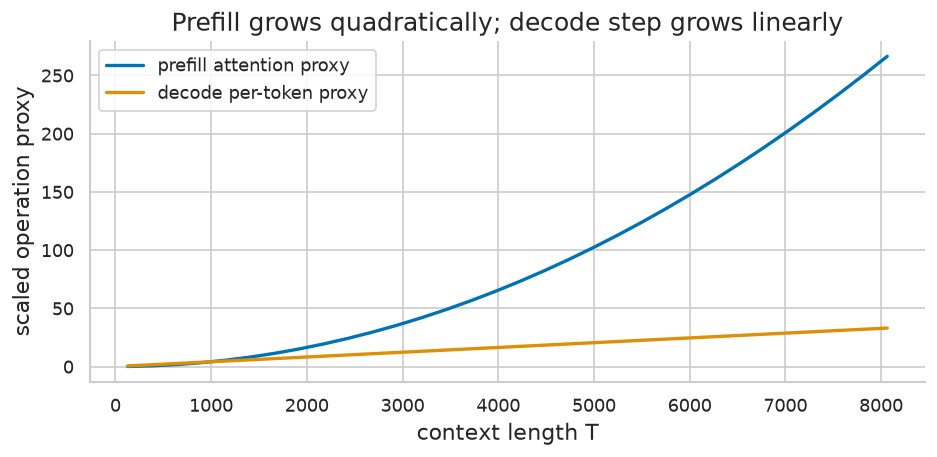

8192-token prefill proxy: 266355081216
8192-token decode proxy: 33030144


In [2]:
T = np.arange(128, 8193, 256)
d = 4096
prefill_ops = T**2 * d
decode_ops_per_token = T * d

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(T, prefill_ops / 1e9, label="prefill attention proxy")
ax.plot(T, decode_ops_per_token / 1e6, label="decode per-token proxy")
ax.set_title("Prefill grows quadratically; decode step grows linearly")
ax.set_xlabel("context length T")
ax.set_ylabel("scaled operation proxy")
ax.legend()
fig.tight_layout()
plt.show()
print("8192-token prefill proxy:", prefill_ops[-1])
print("8192-token decode proxy:", decode_ops_per_token[-1])

## 2. KV cache memory calculator

In [3]:
def kv_cache_gb(batch, layers, tokens, kv_heads, head_dim, bytes_per=2):
    return 2 * batch * layers * tokens * kv_heads * head_dim * bytes_per / 1e9

batch, layers, tokens, q_heads, head_dim = 8, 32, 4096, 32, 128
for kv_heads in [32, 8, 1]:
    print(f"KV heads={kv_heads:>2}: {kv_cache_gb(batch, layers, tokens, kv_heads, head_dim):.2f} GB")

KV heads=32: 17.18 GB
KV heads= 8: 4.29 GB
KV heads= 1: 0.54 GB


## 3. MHA, GQA, and MQA savings

In [4]:
q_heads = 32
kv_options = np.array([32, 16, 8, 4, 1])
savings = q_heads / kv_options
for kv, s in zip(kv_options, savings):
    print(f"H_kv={kv:>2}: cache reduction versus MHA = {s:.1f}x")

H_kv=32: cache reduction versus MHA = 1.0x
H_kv=16: cache reduction versus MHA = 2.0x
H_kv= 8: cache reduction versus MHA = 4.0x
H_kv= 4: cache reduction versus MHA = 8.0x
H_kv= 1: cache reduction versus MHA = 32.0x


## 4. Naive attention-score memory

In [5]:
B, H = 4, 32
lengths = np.array([1024, 2048, 4096, 8192, 16384])
score_gb = B * H * lengths**2 * 2 / 1e9
for T, gb in zip(lengths, score_gb):
    print(f"T={T:>5}: score matrix bf16 memory={gb:8.2f} GB")

T= 1024: score matrix bf16 memory=    0.27 GB
T= 2048: score matrix bf16 memory=    1.07 GB
T= 4096: score matrix bf16 memory=    4.29 GB
T= 8192: score matrix bf16 memory=   17.18 GB
T=16384: score matrix bf16 memory=   68.72 GB


## 5. Online softmax equivalence

In [6]:
scores = np.array([1.2, -0.5, 3.0, 2.2, -1.0, 0.7])
values = np.arange(len(scores), dtype=float)

full = np.exp(scores - scores.max())
full_out = np.sum((full / full.sum()) * values)

m = -np.inf
l = 0.0
weighted = 0.0
for s, v in zip(scores, values):
    m_new = max(m, s)
    l = l * np.exp(m - m_new) + np.exp(s - m_new)
    weighted = weighted * np.exp(m - m_new) + np.exp(s - m_new) * v
    m = m_new
online_out = weighted / l
print("full softmax output:", full_out)
print("online softmax output:", online_out)
print("difference:", abs(full_out - online_out))

full softmax output: 2.241545696508722
online softmax output: 2.241545696508722
difference: 0.0


## 6. Roofline bandwidth intuition

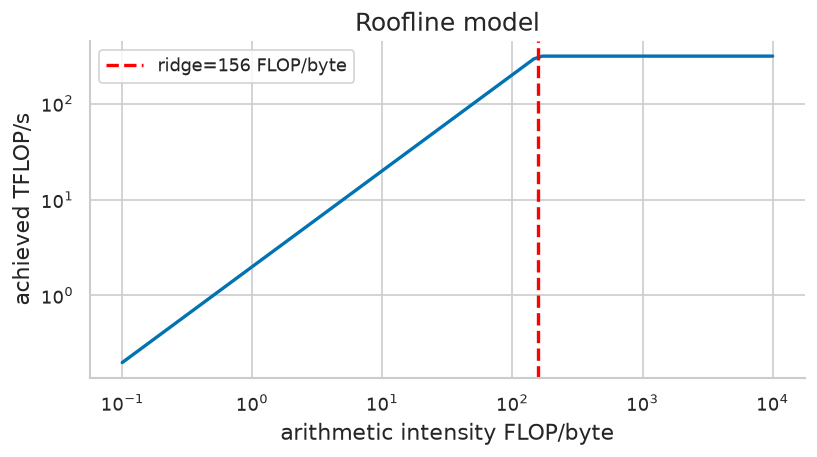

ridge point: 156.0


In [7]:
peak_flops = 312e12
bandwidth = 2e12
ridge = peak_flops / bandwidth
intensity = np.logspace(-1, 4, 80)
achieved = np.minimum(peak_flops, bandwidth * intensity)

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(intensity, achieved / 1e12)
ax.axvline(ridge, color="red", linestyle="--", label=f"ridge={ridge:.0f} FLOP/byte")
ax.set_title("Roofline model")
ax.set_xlabel("arithmetic intensity FLOP/byte")
ax.set_ylabel("achieved TFLOP/s")
ax.legend()
fig.tight_layout()
plt.show()
print("ridge point:", ridge)

## 7. Paged cache waste

In [8]:
lengths = np.array([10, 17, 33, 64, 65, 100])
block = 16
allocated = np.ceil(lengths / block) * block
waste = allocated - lengths
for l, a, w in zip(lengths, allocated, waste):
    print(f"length={l:>3}, allocated={int(a):>3}, waste={int(w):>2}")
print("waste fraction:", waste.sum() / allocated.sum())

length= 10, allocated= 16, waste= 6
length= 17, allocated= 32, waste=15
length= 33, allocated= 48, waste=15
length= 64, allocated= 64, waste= 0
length= 65, allocated= 80, waste=15
length=100, allocated=112, waste=12
waste fraction: 0.17897727272727273


## 8. Continuous batching toy schedule

In [9]:
remaining = np.array([5, 2, 7, 1])
active_counts = []
step = 0
while (remaining > 0).any():
    active = remaining > 0
    active_counts.append(active.sum())
    remaining[active] -= 1
    step += 1
print("active batch size by decode step:", active_counts)
print("average active batch:", np.mean(active_counts))

active batch size by decode step: [np.int64(4), np.int64(3), np.int64(2), np.int64(2), np.int64(2), np.int64(1), np.int64(1)]
average active batch: 2.142857142857143


## 9. Speculative decoding expected speedup

In [10]:
draft_tokens = 4
accept_rates = np.linspace(0.2, 0.95, 8)
draft_cost_fraction = 0.15
for a in accept_rates:
    expected_tokens = 1 + draft_tokens * a
    cost = 1 + draft_cost_fraction * draft_tokens
    speedup = expected_tokens / cost
    print(f"accept={a:.2f}: expected speedup={speedup:.2f}x")

accept=0.20: expected speedup=1.12x
accept=0.31: expected speedup=1.39x
accept=0.41: expected speedup=1.66x
accept=0.52: expected speedup=1.93x
accept=0.63: expected speedup=2.20x
accept=0.74: expected speedup=2.46x
accept=0.84: expected speedup=2.73x
accept=0.95: expected speedup=3.00x


## 10. Latency budget

In [11]:
queue_ms = 12
prefill_ms = 180
output_tokens = 120
tpot_ms = 22
sample_ms = 1
ttft = queue_ms + prefill_ms + sample_ms
total = ttft + output_tokens * tpot_ms
print("TTFT ms:", ttft)
print("total latency ms:", total)
print("tokens/sec after first token:", 1000 / tpot_ms)

TTFT ms: 193
total latency ms: 2833
tokens/sec after first token: 45.45454545454545


## 11. Cached decode correctness check

In [12]:
rng = np.random.default_rng(5)
full = rng.normal(size=(4,))
cached = full + rng.normal(scale=1e-6, size=(4,))
max_diff = np.max(np.abs(full - cached))
print("max difference:", max_diff)
print("pass:", max_diff < 1e-5)

max difference: 1.1360465325127578e-06
pass: True


## 12. Inference debugging checklist

In [13]:
checks = [
    "measure prefill and decode separately",
    "compute KV cache memory from actual batch, context, layers, and KV heads",
    "verify cached decode matches full recomputation on a tiny case",
    "track p50, p95, and p99 latency, not only mean",
    "test quality after quantization or speculative acceleration",
    "attribute bottlenecks to weights, KV cache, kernels, scheduler, or network",
]
for i, check in enumerate(checks, 1):
    print(f"{i}. {check}")

1. measure prefill and decode separately
2. compute KV cache memory from actual batch, context, layers, and KV heads
3. verify cached decode matches full recomputation on a tiny case
4. track p50, p95, and p99 latency, not only mean
5. test quality after quantization or speculative acceleration
6. attribute bottlenecks to weights, KV cache, kernels, scheduler, or network


## New demo: KV cache formula across head configurations (new, notes 11/17)

In [14]:
def kv_bytes(B,L,hkv,dh,s,b=2): return 2*B*L*hkv*dh*s*b
for name,hkv in [("MHA",32),("GQA-8",8),("GQA-4",4),("MQA",1)]:
    print(f"{name}: {kv_bytes(1,32,hkv,128,4096)/1e9:.2f} GB at s=4096")
ok=kv_bytes(1,32,32,128,4096)==4*kv_bytes(1,32,8,128,4096)
print(f"{'PASS' if ok else 'FAIL'} - GQA-8 uses one quarter of MHA cache")

MHA: 2.15 GB at s=4096
GQA-8: 0.54 GB at s=4096
GQA-4: 0.27 GB at s=4096
MQA: 0.07 GB at s=4096
PASS - GQA-8 uses one quarter of MHA cache


## New demo: Online softmax rescaling identity (new, notes 12.2)

In [15]:
vals=np.array([1.0,3.0,4.0]); m=np.max(vals[:2]); ell=np.exp(vals[:2]-m).sum()
m2=max(m,vals[2]); ell2=ell*np.exp(m-m2)+np.exp(vals[2]-m2)
direct=np.exp(vals-vals.max()).sum()
print(f"streaming ell={ell2:.4f}, direct={direct:.4f}")
print(f"{'PASS' if abs(ell2-direct)<1e-12 else 'FAIL'} - online softmax matches direct softmax denominator")

streaming ell=1.4177, direct=1.4177
PASS - online softmax matches direct softmax denominator


## New demo: Speculative acceptance expectation and exactness simulation (new, notes 14/36)

In [16]:
rng=np.random.default_rng(42)
for a,g in [(0.8,4),(0.5,4)]:
    print(f"alpha={a}, gamma={g}: expected accepted={(1-a**(g+1))/(1-a):.2f}")
# simulate the one-token acceptance rule from Sec 36 against a target p
p=np.array([0.5,0.3,0.2]); q=np.array([0.34,0.33,0.33]); n=60000; draws=rng.choice(3,size=n,p=q); u=rng.random(n)
accept=u<np.minimum(1,p[draws]/q[draws]); out=draws.copy()
rej=np.where(~accept)[0]
# correction samples from normalized (p-q)+
corr=np.maximum(p-q,0); corr=corr/corr.sum(); out[rej]=rng.choice(3,size=len(rej),p=corr)
freq=np.bincount(out,minlength=3)/n
print("empirical:",np.round(freq,3),"target:",p)
ok=np.all(np.abs(freq-p)<0.01)
print(f"{'PASS' if ok else 'FAIL'} - draft-verify sampling reproduces the target distribution")

alpha=0.8, gamma=4: expected accepted=3.36
alpha=0.5, gamma=4: expected accepted=1.94
empirical: [0.499 0.3   0.201] target: [0.5 0.3 0.2]
PASS - draft-verify sampling reproduces the target distribution


## New demo: Decode bandwidth floor (new, notes 28)

In [17]:
for name,gb in [("7B",14),("13B",26),("70B",140)]:
    print(f"{name}: bf16 floor {2000/gb:.0f} tok/s, 4-bit floor {2000/(gb/4):.0f} tok/s at 2 TB/s")
print(f"{'PASS' if abs(2000/14-143)<1 else 'FAIL'} - 7B bf16 batch-1 floor is about 143 tokens/s")

7B: bf16 floor 143 tok/s, 4-bit floor 571 tok/s at 2 TB/s
13B: bf16 floor 77 tok/s, 4-bit floor 308 tok/s at 2 TB/s
70B: bf16 floor 14 tok/s, 4-bit floor 57 tok/s at 2 TB/s
PASS - 7B bf16 batch-1 floor is about 143 tokens/s


## New demo: Cache across batch and sequence, plotted (new, notes 23)

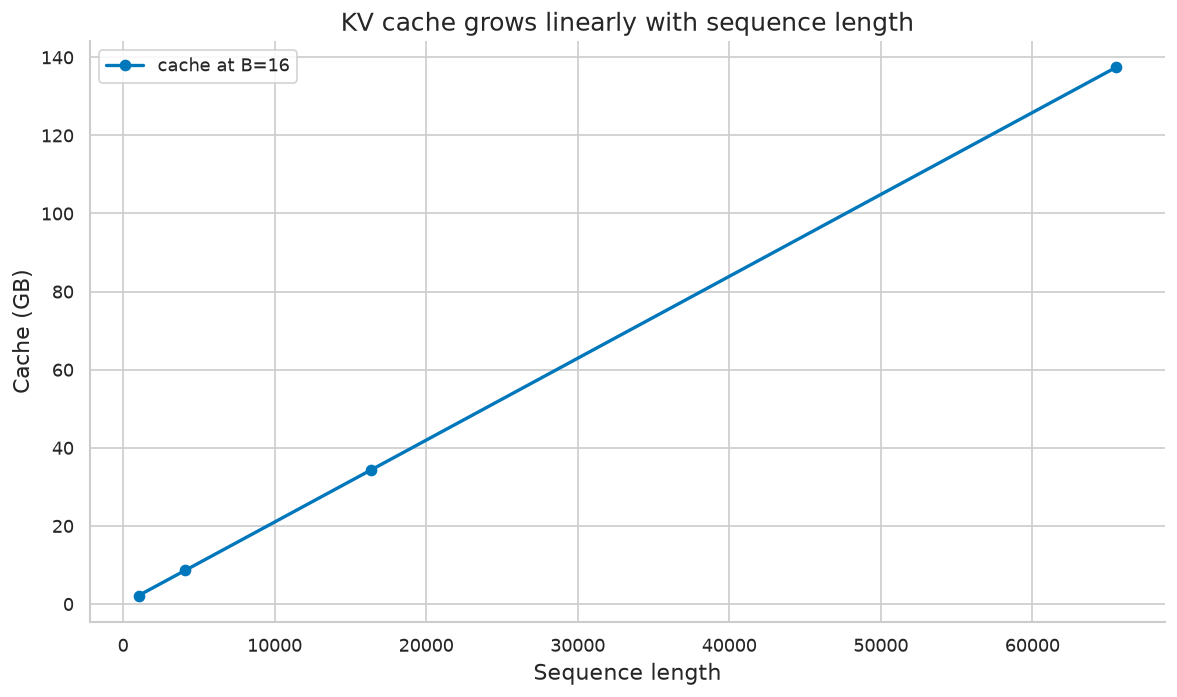

GB: [  2.15   8.59  34.36 137.44]
PASS - cache scales linearly with context


In [18]:
B=16; per_tok=2*32*8*128*2; s=np.array([1024,4096,16384,65536]); gb=per_tok*B*s/1e9
fig, ax = plt.subplots(); ax.plot(s, gb, color="#0077BB", marker="o", label="cache at B=16")
ax.set_title("KV cache grows linearly with sequence length"); ax.set_xlabel("Sequence length"); ax.set_ylabel("Cache (GB)"); ax.legend(loc="best"); fig.tight_layout(); plt.show()
print("GB:",np.round(gb,2))
print(f"{'PASS' if gb[-1]>gb[0] else 'FAIL'} - cache scales linearly with context")

## New demo: TTFT/TPOT workload table (new, notes 39)

In [19]:
for prompt,out in [(128,128),(8192,1024)]:
    ttft=prompt/50000; dec=out*0.025; print(f"prompt={prompt}, out={out}: TTFT={ttft:.3f}s decode={dec:.2f}s total={ttft+dec:.2f}s")
print(f"{'PASS' if abs(8192/50000-0.164)<0.001 else 'FAIL'} - TTFT floor matches prefill arithmetic")

prompt=128, out=128: TTFT=0.003s decode=3.20s total=3.20s
prompt=8192, out=1024: TTFT=0.164s decode=25.60s total=25.76s
PASS - TTFT floor matches prefill arithmetic


## New demo: Prefix sharing saved prefill (new, notes 13.3)

In [20]:
shared=1000; reqs=100; saved=(reqs-1)*shared
print(f"shared prefix {shared} tokens x {reqs} requests saves {saved:,} prefill token computations")
print(f"{'PASS' if saved==99000 else 'FAIL'} - prefix sharing arithmetic")

shared prefix 1000 tokens x 100 requests saves 99,000 prefill token computations
PASS - prefix sharing arithmetic


## New demo: Continuous batching slot reuse, simulated (new, notes 13.2)

In [21]:
lengths=[10,100,1000,50]; static=max(lengths)*len(lengths); cont=sum(lengths)
print(f"static token-steps={static}, continuous token-steps={cont}, utilization gain={static/cont:.2f}x on this toy")
print(f"{'PASS' if cont<static else 'FAIL'} - iteration-level scheduling wastes fewer slots")

static token-steps=4000, continuous token-steps=1160, utilization gain=3.45x on this toy
PASS - iteration-level scheduling wastes fewer slots


## New demo: Weight quantization traffic (new, notes 15)

In [22]:
for bits,frac in [("bf16",1.0),("int8",0.5),("4-bit",0.25)]:
    print(f"7B {bits}: {14*frac:.1f} GB read per token at batch 1")
print(f"{'PASS' if 14*0.25==3.5 else 'FAIL'} - 4-bit weights read 3.5 GB per token")

7B bf16: 14.0 GB read per token at batch 1
7B int8: 7.0 GB read per token at batch 1
7B 4-bit: 3.5 GB read per token at batch 1
PASS - 4-bit weights read 3.5 GB per token


## New demo: Naive attention matrix memory (new, notes 33)

In [23]:
for s in [4096,32768,131072]:
    print(f"s={s}: score matrix per head {s*s*2/1e9:.2f} GB in bf16")
ok=131072**2*2/1e9>30
print(f"{'PASS' if ok else 'FAIL'} - naive 128k attention matrix exceeds 30 GB per head")

s=4096: score matrix per head 0.03 GB in bf16
s=32768: score matrix per head 2.15 GB in bf16
s=131072: score matrix per head 34.36 GB in bf16
PASS - naive 128k attention matrix exceeds 30 GB per head


## New demo: Goodput versus raw throughput (new, notes 50)

In [24]:
raw=1000; meeting_sla=820
print(f"raw throughput {raw} tok/s, goodput at SLA {meeting_sla} tok/s")
print(f"{'PASS' if meeting_sla<raw else 'FAIL'} - goodput never exceeds raw throughput")

raw throughput 1000 tok/s, goodput at SLA 820 tok/s
PASS - goodput never exceeds raw throughput


## New demo: Concurrency from cache budget (new, notes 40)

In [25]:
per_req=2*40*8*128*8192*2/1e9; budget=54
max_req=int(budget//per_req); print(f"per-request cache {per_req:.2f} GB, 54 GB budget -> max {max_req} full-context requests")
print(f"{'PASS' if max_req==40 else 'FAIL'} - sizing example arithmetic (13B GQA config)")

per-request cache 1.34 GB, 54 GB budget -> max 40 full-context requests
PASS - sizing example arithmetic (13B GQA config)
